## Logs and epochs

In [10]:
!ls logs

root_stream_bim_2_shuffle_false_epochs_10_20261110_061713
root_stream_bim_2_shuffle_false_epochs_1_20261110_025522
root_stream_bim_2_shuffle_false_epochs_50_20261110_025958


### Log exploration

In [11]:
import json
from pprint import pprint
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable

In [12]:
FILE_E1 = 'logs/root_stream_bim_2_shuffle_false_epochs_1_20261110_025522/darshan_logs/strategy_stream_bim_2_shuffle_false_batchsize_64_epochs_1/satt_python3_id1749126-1749126_11-10-10523-5712789554778768917_1.darshan.json'

In [13]:
with open(FILE_E1) as file_e1:
    d = json.load(file_e1)
    file_e1.close()
pprint(d)

{'counters': {'DXT_POSIX': {},
              'POSIX': {'counters': ['POSIX_OPENS',
                                     'POSIX_FILENOS',
                                     'POSIX_DUPS',
                                     'POSIX_READS',
                                     'POSIX_WRITES',
                                     'POSIX_SEEKS',
                                     'POSIX_STATS',
                                     'POSIX_MMAPS',
                                     'POSIX_FSYNCS',
                                     'POSIX_FDSYNCS',
                                     'POSIX_RENAME_SOURCES',
                                     'POSIX_RENAME_TARGETS',
                                     'POSIX_RENAMED_FROM',
                                     'POSIX_MODE',
                                     'POSIX_BYTES_READ',
                                     'POSIX_BYTES_WRITTEN',
                                     'POSIX_MAX_BYTE_READ',
                                   

In [14]:
len(d['name_records'])

4271

In [15]:
name_records_raw = d['name_records']
name_records = name_records_raw.items()
name_records_list = list(name_records)
for i in range(10):
    print(name_records_list[i])

('16592106915301738621', 'heatmap:POSIX')
('14734109647742566553', '<STDIN>')
('15920181672442173319', '<STDOUT>')
('7238257241479193519', '<STDERR>')
('3989511027826779520', 'heatmap:STDIO')
('1183378753704768064', '/pscratch/sd/s/satt/sprints/myvenv/pyvenv.cfg')
('2753586021477318973', '/global/common/software/nersc/pe/conda-envs/26.8.0/python-3.13/nersc-python/lib/python3.13/os.py')
('14915634845633470549', '/global/common/software/nersc/pe/conda-envs/26.8.0/python-3.13/nersc-python/lib/python3.13/encodings/__init__.py')
('1279809238936159499', '/global/common/software/nersc/pe/conda-envs/26.8.0/python-3.13/nersc-python/lib/python3.13/encodings/aliases.py')
('14471277080580643569', '/global/common/software/nersc/pe/conda-envs/26.8.0/python-3.13/nersc-python/lib/python3.13/encodings/utf_8.py')


In [16]:
key_roots = [key for key, val in name_records if '9.root' in val]
key_roots

['2684797316911919626']

In [17]:
for i in key_roots:
    print(name_records_raw[i])

/pscratch/sd/s/satt/sprints/data/roots/mc_normalized_rntuple_10M_9.root


In [18]:
key_py = [key for key, val in name_records if '_9.py' in val]
key_py 

['5375169344426660457']

In [19]:
for i in key_py:
    print(name_records_raw[i])

/pscratch/sd/s/satt/sprints/a_star_campaign/root/root_tr_9.py


In [20]:
DXT_POSIX_recs = d['records']['DXT_POSIX']
STDIO_recs = d['records']['STDIO']
POSIX_recs = d['records']['POSIX']

In [21]:
rows_from_POSIX = []
for i in POSIX_recs:
    ide = str(i['id'])
    if ide in key_py or ide in key_roots:
        print(i)
        rows_from_POSIX.append(i)

{'id': 5375169344426660457, 'rank': 0, 'counters': [5, 3, 0, 10, 0, 13, 19, -1, 0, 0, 0, 0, 0, 0, 209394, 0, 105375, 0, 5, 0, 5, 0, 0, 1, 8, 5, 1048576, 105376, 0, 5, 0, 0, 4, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 26953, 105376, 27480, 22632, 2, 1, 1, 1, 0, 0, 0, 0], 'fcounters': [1.1201748847961426, 1.1207022666931152, 0.0, 1.1212108135223389, 6.777878284454346, 6.778013467788696, 0.0, 6.77802300453186, 0.0028641223907470703, 0.0, 0.0024306774139404297, 0.0011806488037109375, 0.0, 0.0, 0.0, 0.0, 0.0]}
{'id': 2684797316911919626, 'rank': 0, 'counters': [3, 0, 0, 43, 0, 5, 4, -1, 0, 0, 0, 0, 0, 0, 1267631508, 0, 1250866430, 0, 9, 0, 32, 0, 0, 14, 8, 40, 1048576, 198846222, 0, 8, 11, 0, 2, 0, 4, 8, 2, 8, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 42, 1246671539, 1246671011, 1250865543, 8, 2, 2, 1, 4194304, 12885, 810, 720, 4, 2, 2, 2, 0, 0, 0, 0], 'fcounters': [19.949809074401855, 19.95001459121704, 0.0, 19.971497297286987, 27.270528554916382, 204.2628092765808, 0

In [22]:
POSIX_counters = d['counters']['POSIX']['counters']
POSIX_counters

['POSIX_OPENS',
 'POSIX_FILENOS',
 'POSIX_DUPS',
 'POSIX_READS',
 'POSIX_WRITES',
 'POSIX_SEEKS',
 'POSIX_STATS',
 'POSIX_MMAPS',
 'POSIX_FSYNCS',
 'POSIX_FDSYNCS',
 'POSIX_RENAME_SOURCES',
 'POSIX_RENAME_TARGETS',
 'POSIX_RENAMED_FROM',
 'POSIX_MODE',
 'POSIX_BYTES_READ',
 'POSIX_BYTES_WRITTEN',
 'POSIX_MAX_BYTE_READ',
 'POSIX_MAX_BYTE_WRITTEN',
 'POSIX_CONSEC_READS',
 'POSIX_CONSEC_WRITES',
 'POSIX_SEQ_READS',
 'POSIX_SEQ_WRITES',
 'POSIX_RW_SWITCHES',
 'POSIX_MEM_NOT_ALIGNED',
 'POSIX_MEM_ALIGNMENT',
 'POSIX_FILE_NOT_ALIGNED',
 'POSIX_FILE_ALIGNMENT',
 'POSIX_MAX_READ_TIME_SIZE',
 'POSIX_MAX_WRITE_TIME_SIZE',
 'POSIX_SIZE_READ_0_100',
 'POSIX_SIZE_READ_100_1K',
 'POSIX_SIZE_READ_1K_10K',
 'POSIX_SIZE_READ_10K_100K',
 'POSIX_SIZE_READ_100K_1M',
 'POSIX_SIZE_READ_1M_4M',
 'POSIX_SIZE_READ_4M_10M',
 'POSIX_SIZE_READ_10M_100M',
 'POSIX_SIZE_READ_100M_1G',
 'POSIX_SIZE_READ_1G_PLUS',
 'POSIX_SIZE_WRITE_0_100',
 'POSIX_SIZE_WRITE_100_1K',
 'POSIX_SIZE_WRITE_1K_10K',
 'POSIX_SIZE_WRITE_10K

In [23]:
POSIX_fcounters = d['counters']['POSIX']['fcounters']
POSIX_fcounters

['POSIX_F_OPEN_START_TIMESTAMP',
 'POSIX_F_READ_START_TIMESTAMP',
 'POSIX_F_WRITE_START_TIMESTAMP',
 'POSIX_F_CLOSE_START_TIMESTAMP',
 'POSIX_F_OPEN_END_TIMESTAMP',
 'POSIX_F_READ_END_TIMESTAMP',
 'POSIX_F_WRITE_END_TIMESTAMP',
 'POSIX_F_CLOSE_END_TIMESTAMP',
 'POSIX_F_READ_TIME',
 'POSIX_F_WRITE_TIME',
 'POSIX_F_META_TIME',
 'POSIX_F_MAX_READ_TIME',
 'POSIX_F_MAX_WRITE_TIME',
 'POSIX_F_FASTEST_RANK_TIME',
 'POSIX_F_SLOWEST_RANK_TIME',
 'POSIX_F_VARIANCE_RANK_TIME',
 'POSIX_F_VARIANCE_RANK_BYTES']

In [24]:
len(rows_from_POSIX[0]['counters']) == len(POSIX_counters)

True

In [25]:
cross_counters_0 = dict(zip(POSIX_counters, rows_from_POSIX[0]['counters']))
pprint(cross_counters_0)

{'POSIX_ACCESS1_ACCESS': 26953,
 'POSIX_ACCESS1_COUNT': 2,
 'POSIX_ACCESS2_ACCESS': 105376,
 'POSIX_ACCESS2_COUNT': 1,
 'POSIX_ACCESS3_ACCESS': 27480,
 'POSIX_ACCESS3_COUNT': 1,
 'POSIX_ACCESS4_ACCESS': 22632,
 'POSIX_ACCESS4_COUNT': 1,
 'POSIX_BYTES_READ': 209394,
 'POSIX_BYTES_WRITTEN': 0,
 'POSIX_CONSEC_READS': 5,
 'POSIX_CONSEC_WRITES': 0,
 'POSIX_DUPS': 0,
 'POSIX_FASTEST_RANK': 0,
 'POSIX_FASTEST_RANK_BYTES': 0,
 'POSIX_FDSYNCS': 0,
 'POSIX_FILENOS': 3,
 'POSIX_FILE_ALIGNMENT': 1048576,
 'POSIX_FILE_NOT_ALIGNED': 5,
 'POSIX_FSYNCS': 0,
 'POSIX_MAX_BYTE_READ': 105375,
 'POSIX_MAX_BYTE_WRITTEN': 0,
 'POSIX_MAX_READ_TIME_SIZE': 105376,
 'POSIX_MAX_WRITE_TIME_SIZE': 0,
 'POSIX_MEM_ALIGNMENT': 8,
 'POSIX_MEM_NOT_ALIGNED': 1,
 'POSIX_MMAPS': -1,
 'POSIX_MODE': 0,
 'POSIX_OPENS': 5,
 'POSIX_READS': 10,
 'POSIX_RENAMED_FROM': 0,
 'POSIX_RENAME_SOURCES': 0,
 'POSIX_RENAME_TARGETS': 0,
 'POSIX_RW_SWITCHES': 0,
 'POSIX_SEEKS': 13,
 'POSIX_SEQ_READS': 5,
 'POSIX_SEQ_WRITES': 0,
 'POSIX_SIZE_

In [26]:
cross_counters_1 = dict(zip(POSIX_counters, rows_from_POSIX[1]['counters']))
pprint(cross_counters_1)

{'POSIX_ACCESS1_ACCESS': 4194304,
 'POSIX_ACCESS1_COUNT': 4,
 'POSIX_ACCESS2_ACCESS': 12885,
 'POSIX_ACCESS2_COUNT': 2,
 'POSIX_ACCESS3_ACCESS': 810,
 'POSIX_ACCESS3_COUNT': 2,
 'POSIX_ACCESS4_ACCESS': 720,
 'POSIX_ACCESS4_COUNT': 2,
 'POSIX_BYTES_READ': 1267631508,
 'POSIX_BYTES_WRITTEN': 0,
 'POSIX_CONSEC_READS': 9,
 'POSIX_CONSEC_WRITES': 0,
 'POSIX_DUPS': 0,
 'POSIX_FASTEST_RANK': 0,
 'POSIX_FASTEST_RANK_BYTES': 0,
 'POSIX_FDSYNCS': 0,
 'POSIX_FILENOS': 0,
 'POSIX_FILE_ALIGNMENT': 1048576,
 'POSIX_FILE_NOT_ALIGNED': 40,
 'POSIX_FSYNCS': 0,
 'POSIX_MAX_BYTE_READ': 1250866430,
 'POSIX_MAX_BYTE_WRITTEN': 0,
 'POSIX_MAX_READ_TIME_SIZE': 198846222,
 'POSIX_MAX_WRITE_TIME_SIZE': 0,
 'POSIX_MEM_ALIGNMENT': 8,
 'POSIX_MEM_NOT_ALIGNED': 14,
 'POSIX_MMAPS': -1,
 'POSIX_MODE': 0,
 'POSIX_OPENS': 3,
 'POSIX_READS': 43,
 'POSIX_RENAMED_FROM': 0,
 'POSIX_RENAME_SOURCES': 0,
 'POSIX_RENAME_TARGETS': 0,
 'POSIX_RW_SWITCHES': 0,
 'POSIX_SEEKS': 5,
 'POSIX_SEQ_READS': 32,
 'POSIX_SEQ_WRITES': 0,
 'P

In [27]:
cross_fcounters_0 = dict(zip(POSIX_fcounters, rows_from_POSIX[0]['fcounters']))
pprint(cross_fcounters_0)

{'POSIX_F_CLOSE_END_TIMESTAMP': 6.77802300453186,
 'POSIX_F_CLOSE_START_TIMESTAMP': 1.1212108135223389,
 'POSIX_F_FASTEST_RANK_TIME': 0.0,
 'POSIX_F_MAX_READ_TIME': 0.0011806488037109375,
 'POSIX_F_MAX_WRITE_TIME': 0.0,
 'POSIX_F_META_TIME': 0.0024306774139404297,
 'POSIX_F_OPEN_END_TIMESTAMP': 6.777878284454346,
 'POSIX_F_OPEN_START_TIMESTAMP': 1.1201748847961426,
 'POSIX_F_READ_END_TIMESTAMP': 6.778013467788696,
 'POSIX_F_READ_START_TIMESTAMP': 1.1207022666931152,
 'POSIX_F_READ_TIME': 0.0028641223907470703,
 'POSIX_F_SLOWEST_RANK_TIME': 0.0,
 'POSIX_F_VARIANCE_RANK_BYTES': 0.0,
 'POSIX_F_VARIANCE_RANK_TIME': 0.0,
 'POSIX_F_WRITE_END_TIMESTAMP': 0.0,
 'POSIX_F_WRITE_START_TIMESTAMP': 0.0,
 'POSIX_F_WRITE_TIME': 0.0}


In [28]:
cross_fcounters_1 = dict(zip(POSIX_fcounters, rows_from_POSIX[1]['fcounters']))
pprint(cross_fcounters_1)

{'POSIX_F_CLOSE_END_TIMESTAMP': 243.7074408531189,
 'POSIX_F_CLOSE_START_TIMESTAMP': 19.971497297286987,
 'POSIX_F_FASTEST_RANK_TIME': 0.0,
 'POSIX_F_MAX_READ_TIME': 0.16652989387512207,
 'POSIX_F_MAX_WRITE_TIME': 0.0,
 'POSIX_F_META_TIME': 0.0005319118499755859,
 'POSIX_F_OPEN_END_TIMESTAMP': 27.270528554916382,
 'POSIX_F_OPEN_START_TIMESTAMP': 19.949809074401855,
 'POSIX_F_READ_END_TIMESTAMP': 204.2628092765808,
 'POSIX_F_READ_START_TIMESTAMP': 19.95001459121704,
 'POSIX_F_READ_TIME': 1.2812299728393555,
 'POSIX_F_SLOWEST_RANK_TIME': 0.0,
 'POSIX_F_VARIANCE_RANK_BYTES': 0.0,
 'POSIX_F_VARIANCE_RANK_TIME': 0.0,
 'POSIX_F_WRITE_END_TIMESTAMP': 0.0,
 'POSIX_F_WRITE_START_TIMESTAMP': 0.0,
 'POSIX_F_WRITE_TIME': 0.0}


### Chronological reconstruction

In [29]:
DXT_TRACE_PATH = 'logs/root_stream_bim_2_shuffle_false_epochs_1_20261110_025522/darshan_logs/strategy_stream_bim_2_shuffle_false_batchsize_64_epochs_1/satt_python3_id1749126-1749126_11-10-10523-5712789554778768917_1.darshan.dxt.txt'

In [30]:
with open(DXT_TRACE_PATH) as trace:
    content = trace.read()
print(content)

# darshan log version: 3.41
# compression method: ZLIB
# exe: /pscratch/sd/s/satt/sprints/myvenv/bin/python3 /pscratch/sd/s/satt/sprints/a_star_campaign/root/root_tr_9.py --data-path /pscratch/sd/s/satt/sprints/data/roots/mc_normalized_rntuple_10M_9.root --tree-name tree --target-col Label --strategy stream --no-shuffle --model M2 --batch-size 64 --epochs 1 --log-every 50000 
# uid: 114163
# jobid: 1749126
# start_time: 1794308123
# start_time_asci: Tue Nov 10 05:55:23 2026
# end_time: 1794308368
# end_time_asci: Tue Nov 10 05:59:28 2026
# nprocs: 1
# run time: 244.7348
# metadata: lib_ver = 3.5.0

# log file regions
# -------------------------------------------------------
# header: 1328 bytes (uncompressed)
# job data: 763 bytes (compressed)
# record table: 75562 bytes (compressed)
# POSIX module: 88208 bytes (compressed), ver=4
# STDIO module: 1872 bytes (compressed), ver=2
# DXT_POSIX module: 7835 bytes (compressed), ver=2
# HEATMAP module: 263 bytes (compressed), ver=1

# mounted 

In [31]:
keys_all = []
keys_all.append([key_roots, key_py])

In [32]:
keys_all = sum(sum(keys_all, []),[])
keys_all

['2684797316911919626', '5375169344426660457']

In [33]:
dxt_section = content.split("# DXT_POSIX module data")[1]
print(dxt_section)


# ***************************************************

# DXT, file_id: 1183378753704768064, file_name: /pscratch/sd/s/satt/sprints/myvenv/pyvenv.cfg
# DXT, rank: 0, hostname: nid004290
# DXT, number of threads: 1
# DXT, write_count: 0, read_count: 4
# DXT, mnt_pt: /pscratch, fs_type: lustre
# Module    Rank  Wt/Rd  Segment          Offset          Length    Start(s)      End(s)   Pthread-ID
 X_POSIX       0   read        0               0            6339      0.2816      0.2837   140470341297984
 X_POSIX       0   read        1            6339               0      0.2837      0.2837   140470341297984
 X_POSIX       0   read        2               0             387      0.3146      0.3147   140470341297984
 X_POSIX       0   read        3             387               0      0.3147      0.3147   140470341297984

# DXT, file_id: 6509654755798325290, file_name: /pscratch/sd/s/satt/sprints/myvenv/lib/python3.13/site-packages/distutils-precedence.pth
# DXT, rank: 0, hostname: nid004290
# D

In [34]:
blocks = re.split(
    r"(?=^# DXT, file_id:)",
    dxt_section,
    flags=re.MULTILINE
)

In [35]:
selected = []
for block in blocks:
    match = re.match(r"# DXT, file_id:\s*(\d+)", block.lstrip())

    if match and match.group(1) in {str(k) for k in keys_all}:
        selected.append(block.strip())
print(selected)

['# DXT, file_id: 5375169344426660457, file_name: /pscratch/sd/s/satt/sprints/a_star_campaign/root/root_tr_9.py\n# DXT, rank: 0, hostname: nid004290\n# DXT, number of threads: 1\n# DXT, write_count: 0, read_count: 10\n# DXT, mnt_pt: /pscratch, fs_type: lustre\n# Module    Rank  Wt/Rd  Segment          Offset          Length    Start(s)      End(s)   Pthread-ID\n X_POSIX       0   read        0               0           26953      1.1207      1.1211   140470341297984\n X_POSIX       0   read        1           26953               0      1.1212      1.1212   140470341297984\n X_POSIX       0   read        2               0          105376      1.1268      1.1280   140470341297984\n X_POSIX       0   read        3          105376               0      1.1280      1.1280   140470341297984\n X_POSIX       0   read        4               0           22632      1.1299      1.1307   140470341297984\n X_POSIX       0   read        5           22632               0      1.1307      1.1307   14047

In [36]:
def parse_dxt_block(block):
    
    def extract(pattern):
        match = re.search(pattern, block, re.MULTILINE)
        if not match:
            raise ValueError(f"Missing field: {pattern}")
        return match.groups()
    
    file_id, file_name = extract(
        r"^# DXT, file_id:\s*(\d+), file_name:\s*(.+)$"
    )

    rank, hostname = extract(
        r"^# DXT, rank:\s*(-?\d+), hostname:\s*(.+)$"
    )

    (nthreads,) = extract(
        r"^# DXT, number of threads:\s*(\d+)$"
    )

    write_count, read_count = extract(
        r"^# DXT, write_count:\s*(\d+), read_count:\s*(\d+)$"
    )

    mnt_pt, fs_type = extract(
        r"^# DXT, mnt_pt:\s*(.*?), fs_type:\s*(.+)$"
    )

    rows = []

    for line in block.splitlines():
        cols = line.split()

        if not cols or cols[0] != "X_POSIX":
            continue
            
        if len(cols) != 9:
            raise ValueError(f"Invalid DXT row: {line}")
        
        module, row_rank, operation, segment, offset, length, start, end, pthread = cols

        rows.append({
            "module": module,
            "rank": int(row_rank),
            "operation": operation,
            "segment": int(segment),
            "offset": int(offset),
            "length": int(length),
            "start_s": float(start),
            "end_s": float(end),
            "pthread_id": None if pthread == "-1" else pthread
        })

    result = {
        "file_id": file_id,
        "file_name": file_name,
        "rank": int(rank),
        "hostname": hostname,
        "nthreads": int(nthreads),
        "write_count": int(write_count),
        "read_count": int(read_count),
        "mnt_pt": mnt_pt,
        "fs_type": fs_type,
        "rows": rows
    }

    return result

dxt_data = [parse_dxt_block(block) for block in selected]
        

In [37]:
dxt_data

[{'file_id': '5375169344426660457',
  'file_name': '/pscratch/sd/s/satt/sprints/a_star_campaign/root/root_tr_9.py',
  'rank': 0,
  'hostname': 'nid004290',
  'nthreads': 1,
  'write_count': 0,
  'read_count': 10,
  'mnt_pt': '/pscratch',
  'fs_type': 'lustre',
  'rows': [{'module': 'X_POSIX',
    'rank': 0,
    'operation': 'read',
    'segment': 0,
    'offset': 0,
    'length': 26953,
    'start_s': 1.1207,
    'end_s': 1.1211,
    'pthread_id': '140470341297984'},
   {'module': 'X_POSIX',
    'rank': 0,
    'operation': 'read',
    'segment': 1,
    'offset': 26953,
    'length': 0,
    'start_s': 1.1212,
    'end_s': 1.1212,
    'pthread_id': '140470341297984'},
   {'module': 'X_POSIX',
    'rank': 0,
    'operation': 'read',
    'segment': 2,
    'offset': 0,
    'length': 105376,
    'start_s': 1.1268,
    'end_s': 1.128,
    'pthread_id': '140470341297984'},
   {'module': 'X_POSIX',
    'rank': 0,
    'operation': 'read',
    'segment': 3,
    'offset': 105376,
    'length': 0,


In [38]:
with open("filtered_dxt_1.json", "w") as f:
    json.dump(dxt_data, f)

In [39]:
# Verify 
for record in dxt_data:
    reads = sum(
        row["operation"] == "read"
        for row in record["rows"]
    )

    writes = sum(
        row["operation"] == "write"
        for row in record["rows"]
    )

    assert reads == record["read_count"]
    assert writes == record["write_count"]

    print(record["file_name"])
    print(f"  Reads:  {reads}")
    print(f"  Writes: {writes}")
    print(f"  Threads: {record['nthreads']}")

/pscratch/sd/s/satt/sprints/a_star_campaign/root/root_tr_9.py
  Reads:  10
  Writes: 0
  Threads: 1
/pscratch/sd/s/satt/sprints/data/roots/mc_normalized_rntuple_10M_9.root
  Reads:  43
  Writes: 0
  Threads: 2


In [40]:
root_data = next(
    record for record in dxt_data
    if record["file_name"].endswith(
        ".root"
    )
)

df_root = pd.DataFrame(root_data["rows"])

df_root

,module,rank,operation,segment,offset,length,start_s,end_s,pthread_id
0,X_POSIX,0,read,0,0,300,19.9500,19.9511,140470341297984
1,X_POSIX,0,read,1,1250865843,125,19.9512,19.9515,140470341297984
2,X_POSIX,0,read,2,1250865968,386,19.9515,19.9515,140470341297984
3,X_POSIX,0,read,3,1250865711,132,19.9569,19.9569,140470341297984
4,X_POSIX,0,read,4,1250865711,132,19.9569,19.9569,140470341297984
5,X_POSIX,0,read,5,0,4194304,19.9577,19.9645,140470341297984
6,X_POSIX,0,read,6,1250865843,588,19.9646,19.9646,140470341297984
7,X_POSIX,0,read,7,1250866431,0,19.9646,19.9646,140470341297984
8,X_POSIX,0,read,8,1250865711,720,19.9646,19.9646,140470341297984
9,X_POSIX,0,read,9,1250866431,0,19.9646,19.9646,140470341297984


In [41]:
py_data = next(
    record for record in dxt_data
    if record["file_name"].endswith(
        ".py"
    )
)

df_py = pd.DataFrame(py_data["rows"])

df_py

,module,rank,operation,segment,offset,length,start_s,end_s,pthread_id
0,X_POSIX,0,read,0,0,26953,1.1207,1.1211,140470341297984
1,X_POSIX,0,read,1,26953,0,1.1212,1.1212,140470341297984
2,X_POSIX,0,read,2,0,105376,1.1268,1.1280,140470341297984
3,X_POSIX,0,read,3,105376,0,1.1280,1.1280,140470341297984
4,X_POSIX,0,read,4,0,22632,1.1299,1.1307,140470341297984
5,X_POSIX,0,read,5,22632,0,1.1307,1.1307,140470341297984
6,X_POSIX,0,read,6,0,27480,1.1345,1.1349,140470341297984
7,X_POSIX,0,read,7,27480,0,1.1349,1.1349,140470341297984
8,X_POSIX,0,read,8,0,26953,6.7779,6.7779,140470341297984
9,X_POSIX,0,read,9,26953,0,6.7780,6.7780,140470341297984


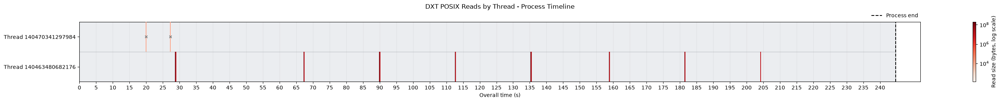

In [42]:
runtime = d["metadata"]["job"]["run_time"]

dataset_record = next(
    record for record in dxt_data
    if record["file_name"].endswith("mc_normalized_rntuple_10M_9.root")
)

reads = sorted(
    [row for row in dataset_record["rows"]
     if row["operation"] == "read"],
    key=lambda row: row["start_s"]
)

positive_lengths = [r["length"] for r in reads if r["length"] > 0]

norm = mcolors.LogNorm(
    vmin=min(positive_lengths),
    vmax=max(positive_lengths)
)

cmap = plt.get_cmap("Reds")

# Group reads by thread
thread_ids = sorted({str(r["pthread_id"]) for r in reads})
thread_reads = {
    tid: [r for r in reads if str(r["pthread_id"]) == tid]
    for tid in thread_ids
}

fig, ax = plt.subplots(figsize=(30, 2.8))

lane_height = 0.8

# Contiguous thread lanes
lane_bottoms = {
    tid: i * lane_height
    for i, tid in enumerate(thread_ids)
}

for tid in thread_ids:
    y0 = lane_bottoms[tid]

    # Full process duration background
    ax.broken_barh(
        [(0, runtime)],
        (y0, lane_height),
        facecolors="#ebedf0",
        edgecolors="#c8ccd1",
        zorder=1
    )

    # Read intervals
    for row in thread_reads[tid]:
        start = row["start_s"]
        end = row["end_s"]
        length = row["length"]
        duration = end - start

        if length == 0:
            ax.plot(
                start,
                y0 + lane_height / 2,
                "x",
                color="gray",
                markersize=5,
                zorder=5
            )
            continue

        color = cmap(norm(length))

        if duration > 0:
            ax.broken_barh(
                [(start, duration)],
                (y0, lane_height),
                facecolors=color,
                edgecolors="none",
                zorder=3
            )

        # Start marker for visibility
        ax.vlines(
            start,
            y0,
            y0 + lane_height,
            color=color,
            linewidth=1.2,
            zorder=4
        )

# Process end marker
ax.axvline(
    runtime,
    color="black",
    linestyle="--",
    label="Process end",
    zorder=6
)

ax.set_xlim(0, runtime * 1.03)
ax.set_ylim(0, lane_height * len(thread_ids))

# X-axis ticks every 5 seconds
ax.set_xticks(range(0, int(runtime) + 1, 5))

# Actual thread IDs
ax.set_yticks([
    lane_bottoms[tid] + lane_height / 2
    for tid in thread_ids
])
ax.set_yticklabels([
    f"Thread {tid}"
    for tid in thread_ids
])

ax.set_xlabel("Overall time (s)")
ax.set_title(
    "DXT POSIX Reads by Thread - Process Timeline",
    pad=25
)

ax.grid(axis="x", alpha=0.2)

# Logarithmic read-size colorbar
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Read size (bytes, log scale)")

# Legend outside the plotting area
ax.legend(
    loc="lower right",
    bbox_to_anchor=(1, 1.02),
    frameon=False,
    borderaxespad=0
)

plt.tight_layout()
plt.savefig(
    "dxt_two_thread_timeline_contiguous_root.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

Selected application events: 13
   18.843s  main_start
   18.859s  train_start
   24.829s  loader_build_start
   24.829s  loader_build_end
   24.829s  epoch_start
   29.984s  first_batch_received
   30.335s  first_batch_processed
   99.567s  batch_checkpoint
  167.993s  batch_checkpoint
  235.366s  batch_checkpoint
  243.557s  epoch_end
  243.558s  train_end
  243.558s  main_end


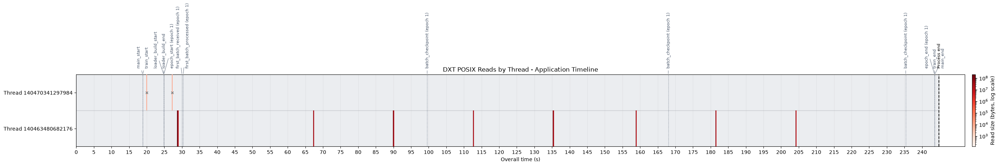

In [43]:
# ---------------------------------------------------------
# 1. Load and select application events
# ---------------------------------------------------------

LOG_PATH = Path("logs/root_stream_bim_2_shuffle_false_epochs_1_20261110_025522/logs/log.strategy_stream_bim_2_shuffle_false_batchsize_64_epochs_1.txt")

selected_event_names = {
    "main_start",
    "train_start",
    "loader_build_start",
    "loader_build_end",
    "epoch_start",
    "epoch_end",
    "first_batch_received",
    "first_batch_processed",
    "batch_checkpoint",
    "train_end",
    "main_end",
}

job = d["metadata"]["job"]

darshan_start_ns = (
    int(job["start_time_sec"]) * 1_000_000_000
    + int(job["start_time_nsec"])
)

runtime = job["run_time"]

events = []

with LOG_PATH.open("r", encoding="utf-8") as f:
    for line in f:
        if not line.startswith("TRACE_EVENT "):
            continue

        event = json.loads(line[len("TRACE_EVENT "):])

        if event["event"] not in selected_event_names:
            continue

        event["time_s"] = (
            int(event["unix_ns"]) - darshan_start_ns
        ) / 1_000_000_000

        events.append(event)

events.sort(key=lambda e: e["time_s"])

if not events:
    raise ValueError("No selected TRACE_EVENT records were found.")

if any(e["time_s"] < 0 or e["time_s"] > runtime for e in events):
    raise ValueError(
        "Application events fall outside the Darshan runtime. "
        "Check that both files belong to the same execution."
    )

print(f"Selected application events: {len(events)}")

for event in events:
    print(f"{event['time_s']:9.3f}s  {event['event']}")


# ---------------------------------------------------------
# 2. Prepare DXT read operations
# ---------------------------------------------------------

dataset_record = next(
    record for record in dxt_data
    if record["file_name"].endswith("mc_normalized_rntuple_10M_9.root")
)

reads = sorted(
    [row for row in dataset_record["rows"]
     if row["operation"] == "read"],
    key=lambda row: row["start_s"]
)

positive_lengths = [r["length"] for r in reads if r["length"] > 0]

norm = mcolors.LogNorm(
    vmin=min(positive_lengths),
    vmax=max(positive_lengths)
)

cmap = plt.get_cmap("Reds")

thread_ids = sorted({str(r["pthread_id"]) for r in reads})

thread_reads = {
    tid: [r for r in reads if str(r["pthread_id"]) == tid]
    for tid in thread_ids
}


# ---------------------------------------------------------
# 3. Build contiguous thread lanes
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(30, 6))

lane_height = 0.8

lane_bottoms = {
    tid: i * lane_height
    for i, tid in enumerate(thread_ids)
}

for tid in thread_ids:
    y0 = lane_bottoms[tid]

    ax.broken_barh(
        [(0, runtime)],
        (y0, lane_height),
        facecolors="#ebedf0",
        edgecolors="#c8ccd1",
        zorder=1
    )

    for row in thread_reads[tid]:
        start = row["start_s"]
        end = row["end_s"]
        length = row["length"]
        duration = end - start

        if length == 0:
            ax.plot(
                start,
                y0 + lane_height / 2,
                "x",
                color="gray",
                markersize=5,
                zorder=5
            )
            continue

        color = cmap(norm(length))

        if duration > 0:
            ax.broken_barh(
                [(start, duration)],
                (y0, lane_height),
                facecolors=color,
                edgecolors="none",
                zorder=3
            )

        ax.vlines(
            start,
            y0,
            y0 + lane_height,
            color=color,
            linewidth=1.2,
            zorder=4
        )


# ---------------------------------------------------------
# 4. Application event lines
# ---------------------------------------------------------

event_line_color = "#475569"

for event in events:
    ax.axvline(
        event["time_s"],
        color=event_line_color,
        linestyle=":",
        linewidth=1,
        alpha=0.8,
        zorder=6
    )


# ---------------------------------------------------------
# 5. Process end
# ---------------------------------------------------------

ax.axvline(
    runtime,
    color="black",
    linestyle="--",
    linewidth=1.4,
    zorder=7
)


# ---------------------------------------------------------
# 6. Axes
# ---------------------------------------------------------

ax.set_xlim(0, runtime * 1.03)
ax.set_ylim(0, lane_height * len(thread_ids))

tick_step = (
    5 if runtime <= 600
    else 30 if runtime <= 3600
    else 120
)

ax.set_xticks(range(0, int(runtime) + 1, tick_step))

ax.set_yticks([
    lane_bottoms[tid] + lane_height / 2
    for tid in thread_ids
])

ax.set_yticklabels([
    f"Thread {tid}"
    for tid in thread_ids
])

ax.set_xlabel("Overall time (s)")
ax.set_title("DXT POSIX Reads by Thread - Application Timeline")

ax.grid(axis="x", alpha=0.2)


# ---------------------------------------------------------
# 7. Read-size colorbar
# ---------------------------------------------------------

sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    fraction=0.012,
    pad=0.008
)

cbar.set_label("Read size (bytes, log scale)")


# ---------------------------------------------------------
# 8. Vertical event labels above the plot
# ---------------------------------------------------------

# Leave sufficient room above the timeline
fig.subplots_adjust(
    left=0.12,
    right=0.95,
    bottom=0.14,
    top=0.47
)

fig.canvas.draw()

# Group labels that would overlap horizontally
# using their actual display positions
event_groups = []
current_group = []

min_spacing_px = 22

for event in events:
    x_px = ax.transData.transform((event["time_s"], 0))[0]

    if current_group and x_px - current_group[-1][1] >= min_spacing_px:
        event_groups.append(current_group)
        current_group = []

    current_group.append((event, x_px))

if current_group:
    event_groups.append(current_group)

# Place rotated labels with small horizontal offsets
# while keeping event lines at their true timestamps
for group in event_groups:
    n = len(group)

    for i, (event, _) in enumerate(group):
        label = event["event"]

        if "epoch" in event:
            label += f" (epoch {event['epoch']})"

        offset_pt = (i - (n - 1) / 2) * 16

        ax.annotate(
            label,
            xy=(event["time_s"], 1.0),
            xycoords=("data", "axes fraction"),
            xytext=(offset_pt, 12),
            textcoords="offset points",
            rotation=90,
            ha="center",
            va="bottom",
            fontsize=8,
            color=event_line_color,
            annotation_clip=False,
            arrowprops=dict(
                arrowstyle="-",
                color=event_line_color,
                linewidth=0.6
            )
        )

# Label the process end directly
ax.annotate(
    "Process end",
    xy=(runtime, 1.0),
    xycoords=("data", "axes fraction"),
    xytext=(0, 12),
    textcoords="offset points",
    rotation=90,
    ha="center",
    va="bottom",
    fontsize=8,
    color="black",
    annotation_clip=False
)


# ---------------------------------------------------------
# 9. Save
# ---------------------------------------------------------

plt.savefig(
    "dxt_threads_with_vertical_events.png",
    dpi=180,
    bbox_inches="tight"
)

plt.savefig(
    "dxt_threads_with_vertical_events.svg",
    bbox_inches="tight"
)

plt.show()